In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from pyod.models.auto_encoder import AutoEncoder
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve , auc , accuracy_score
from sklearn.metrics import (precision_recall_curve, roc_curve, roc_auc_score,
                             accuracy_score, precision_score, recall_score, f1_score)
from pyod.models.auto_encoder import AutoEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from pyod.models.auto_encoder import AutoEncoder
from pyod.models.lof import LOF

import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from pyod.models.auto_encoder import AutoEncoder
from pyod.models.lof import LOF as PyOD_LOF  
from sklearn.model_selection import GridSearchCV 
from pyod.models.iforest import IForest
from pyod.models.auto_encoder import AutoEncoder
import numpy as np
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, f1_score, accuracy_score, 
    roc_curve, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt


In [8]:
data_scaled = pd.read_csv("scaled_training_dataset.csv")
data_test_scaled = pd.read_csv("scaled_test_dataset.csv")

## LOF +autoencoder on card features

In [6]:


def find_best_lof_neighbors(X, contamination=0.006):
    """
    Finds the best number of neighbors for LOF using GridSearchCV.

    Parameters:
    - X: Input data (usually anomaly scores)
    - contamination: Contamination parameter for LOF

    Returns:
    - best_n_neighbors: Optimal number of neighbors
    """
    param_grid = {'n_neighbors': range(5, 30, 5)}
    
    lof = PyOD_LOF(contamination=contamination)
    
    grid_search = GridSearchCV(lof, param_grid, scoring='accuracy', cv=5)
    grid_search.fit(X)
    
    best_n_neighbors = grid_search.best_params_['n_neighbors']
    return best_n_neighbors

def calculate_beta_weighted_threshold(y_true, scores, beta=1.0):
    """
    Calculate the beta-weighted threshold for anomaly detection.

    Parameters:
    - y_true: True labels
    - scores: Anomaly scores
    - beta: Weight of recall in the threshold calculation (default is 1.0)

    Returns:
    - threshold: The optimal threshold
    """
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    fbeta_scores = (1 + beta**2) * (precision * recall) / (beta**2 * precision + recall)
    optimal_idx = np.argmax(fbeta_scores)
    return thresholds[optimal_idx]

def calculate_best_f1_threshold(y_true, scores):
    """
    Calculate the threshold that maximizes the F1 score for anomaly detection.

    Parameters:
    - y_true: True labels
    - scores: Anomaly scores

    Returns:
    - threshold: The optimal threshold for maximizing F1 score
    """
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1_scores = 2 * (precision * recall) / (precision + recall)
    optimal_idx = np.argmax(f1_scores)
    return thresholds[optimal_idx]

def anomaly_detection_with_autoencoder_lof_optimized(data_scaled, data_test_scaled, selected_features, target='is_fraud', beta=1.0):
    """
    Optimized anomaly detection function using PyOD AutoEncoder and LOF with beta-weighted and F1 score-based thresholds, and optimal neighbors.
    """
    X_train = data_scaled[selected_features]
    X_test = data_test_scaled[selected_features]
    y_test = data_test_scaled[target]
    
    autoencoder = AutoEncoder(lr=0.001, contamination=0.006)
    autoencoder.fit(X_train)
    
    autoencoder_train_scores = autoencoder.decision_function(X_train)
    print(f"AutoEncoder train scores mean: {np.mean(autoencoder_train_scores)}, std: {np.std(autoencoder_train_scores)}")
    
    best_n_neighbors = find_best_lof_neighbors(autoencoder_train_scores.reshape(-1, 1))
    print(f"Best number of neighbors for LOF: {best_n_neighbors}")
    lof = PyOD_LOF(n_neighbors=best_n_neighbors, contamination=0.006)
    lof.fit(autoencoder_train_scores.reshape(-1, 1))
    
    autoencoder_test_scores = autoencoder.decision_function(X_test)
    print(f"AutoEncoder test scores mean: {np.mean(autoencoder_test_scores)}, std: {np.std(autoencoder_test_scores)}")
    
    lof_test_scores = lof.decision_function(autoencoder_test_scores.reshape(-1, 1))
    
    beta_threshold = calculate_beta_weighted_threshold(y_test, lof_test_scores, beta)
    f1_threshold = calculate_best_f1_threshold(y_test, lof_test_scores)
    print(f"Beta-weighted threshold: {beta_threshold}")
    print(f"F1 score-based threshold: {f1_threshold}")
    
    lof_preds_beta = (lof_test_scores < beta_threshold).astype(int)  
    lof_preds_f1 = (lof_test_scores < f1_threshold).astype(int)  
    
    comparison_df = pd.DataFrame({
        'Anomaly_Score': lof_test_scores,
        'True_Label': y_test,
        'Predicted_Anomaly_Beta': lof_preds_beta,
        'Predicted_Anomaly_F1': lof_preds_f1
    })
    
    print(f"DataFrame created with {comparison_df.shape[0]} rows.")
    print(comparison_df.head())
    
    accuracy_beta = accuracy_score(y_test, lof_preds_beta)
    precision_beta = precision_score(y_test, lof_preds_beta)
    recall_beta = recall_score(y_test, lof_preds_beta)
    f1_beta = f1_score(y_test, lof_preds_beta)
    roc_auc_beta = roc_auc_score(y_test, lof_preds_beta)
    
    print("Evaluation metrics for Beta-Weighted Threshold:")
    print(f"Accuracy: {accuracy_beta:.4f}")
    print(f"Precision: {precision_beta:.4f}")
    print(f"Recall: {recall_beta:.4f}")
    print(f"F1 Score: {f1_beta:.4f}")
    print(f"ROC AUC Score: {roc_auc_beta:.4f}")
    
    accuracy_f1 = accuracy_score(y_test, lof_preds_f1)
    precision_f1 = precision_score(y_test, lof_preds_f1)
    recall_f1 = recall_score(y_test, lof_preds_f1)
    f1_f1 = f1_score(y_test, lof_preds_f1)
    roc_auc_f1 = roc_auc_score(y_test, lof_preds_f1)
    
    print("Evaluation metrics for F1 Score-Based Threshold:")
    print(f"Accuracy: {accuracy_f1:.4f}")
    print(f"Precision: {precision_f1:.4f}")
    print(f"Recall: {recall_f1:.4f}")
    print(f"F1 Score: {f1_f1:.4f}")
    print(f"ROC AUC Score: {roc_auc_f1:.4f}")
    
    cm_beta = confusion_matrix(y_test, lof_preds_beta)
    cm_f1 = confusion_matrix(y_test, lof_preds_f1)
    
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    sns.heatmap(cm_beta, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix (Beta-Weighted Threshold)')
    
    plt.subplot(1, 2, 2)
    sns.heatmap(cm_f1, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix (F1 Score-Based Threshold)')
    
    plt.show()

    return comparison_df




Training: 100%|██████████| 10/10 [27:53<00:00, 167.40s/it]


AutoEncoder train scores mean: 0.5592352151870728, std: 0.33560729026794434
Best number of neighbors for LOF: 5
AutoEncoder test scores mean: 0.6126994490623474, std: 0.3602650761604309
Beta-weighted threshold: 4.520082473754883
F1 score-based threshold: 4.520082473754883
DataFrame created with 554795 rows.
   Anomaly_Score  True_Label  Predicted_Anomaly_Beta  Predicted_Anomaly_F1
0       1.130563           0                       1                     1
1       1.148639           0                       1                     1
2       1.105742           0                       1                     1
3       1.820741           0                       1                     1
4       0.975019           0                       1                     1
Evaluation metrics for Beta-Weighted Threshold:
Accuracy: 0.0041
Precision: 0.0038
Recall: 1.0000
F1 Score: 0.0076
ROC AUC Score: 0.5001
Evaluation metrics for F1 Score-Based Threshold:
Accuracy: 0.0041
Precision: 0.0038
Recall: 1.0000
F1 Sc

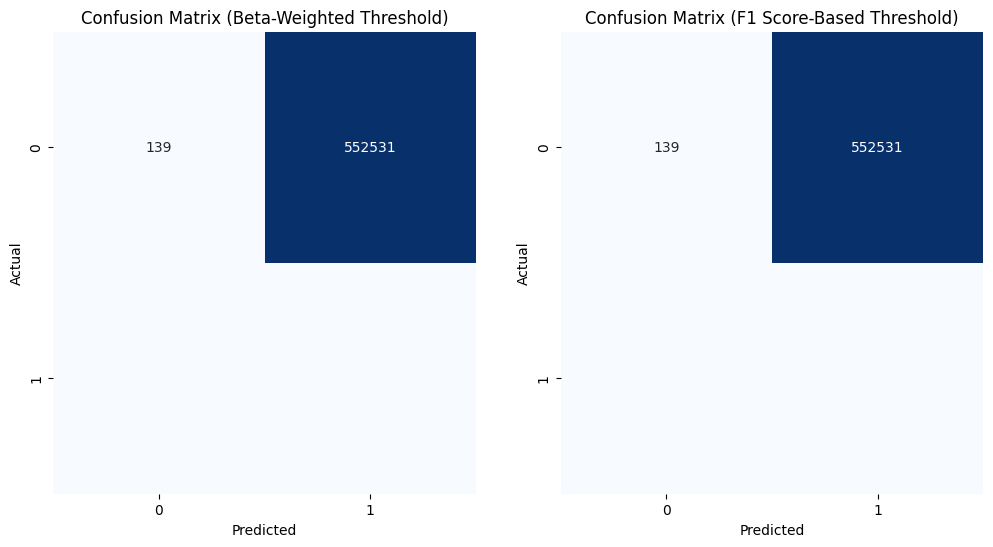

   Anomaly_Score  True_Label  Predicted_Anomaly_Beta  Predicted_Anomaly_F1
0       1.130563           0                       1                     1
1       1.148639           0                       1                     1
2       1.105742           0                       1                     1
3       1.820741           0                       1                     1
4       0.975019           0                       1                     1


In [7]:
selected_card_features = [
    'category_diversity', 'amt_rolling_mean_7d', 'age_spend_ratio', 'amt',
    'amt_rolling_mean_15d', 'avg_daily_trans', 'num_trans_per_card',
    'distance_between_transactions', 'distance_between_cardholder_merchant'
]

comparison_df = anomaly_detection_with_autoencoder_lof_optimized(
    data_scaled=data_scaled,
    data_test_scaled=data_test_scaled,
    selected_features=selected_card_features,
    target='is_fraud',
    beta=0.5 
)

print(comparison_df.head())

## Isolation forest +autoencoder

In [17]:
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score, accuracy_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
from pyod.models.iforest import IForest
from pyod.models.auto_encoder import AutoEncoder

def find_best_threshold(y_true, y_scores, thresholds):
    """
    Find the best threshold that maximizes the F1 score.

    Parameters:
    y_true (array-like): Ground truth binary labels (0 or 1).
    y_scores (array-like): Predicted scores or probabilities.
    thresholds (array-like): Array of threshold values to evaluate.

    Returns:
    best_threshold (float): The threshold value that yields the highest F1 score.
    best_f1 (float): The highest F1 score obtained.
    """
    best_threshold = 0.0
    best_f1 = 0.0

    for threshold in thresholds:
        y_pred = (y_scores > threshold).astype(int)
        f1 = f1_score(y_true, y_pred)
        
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            
    return best_threshold, best_f1

def autoencoder_on_iforest_anomalies(result_df, selected_features, contamination=0.006, search_best_threshold=True):
    """
    Apply an Autoencoder on features combined with Isolation Forest anomaly scores, 
    and optionally find the best threshold for classification.

    Parameters:
    result_df (pd.DataFrame): The input DataFrame containing the features and the 'is_fraud' label.
    selected_features (list of str): List of feature column names to be used for the model.
    contamination (float): The proportion of anomalies in the data. Default is 0.006.
    search_best_threshold (bool): If True, find the best threshold that maximizes F1 score. Default is True.

    Returns:
    result_df_filtered (pd.DataFrame): A DataFrame containing the features, is_fraud label, anomaly scores, and potential anomaly flags.
    best_threshold (float): The best threshold value found or the default threshold from the Autoencoder.
    """
    X = result_df[selected_features].values
    
    isolation_forest = IForest(contamination=contamination, random_state=42)
    isolation_forest.fit(X)
    
    anomaly_scores_iforest = isolation_forest.decision_function(X) * -1  
    X_combined = np.hstack((X, anomaly_scores_iforest.reshape(-1, 1)))
    
    result_df_autoencoder = result_df.copy()
    result_df_autoencoder['anomaly_score_iforest'] = anomaly_scores_iforest
    
    autoencoder = AutoEncoder(contamination=contamination, random_state=42)
    autoencoder.fit(X_combined)
    
    anomaly_scores_autoencoder = autoencoder.decision_function(X_combined)
    result_df_autoencoder['anomaly_score_autoencoder'] = anomaly_scores_autoencoder
    
    if search_best_threshold:
        thresholds = np.linspace(0, 1, 100)
        best_threshold, best_f1 = find_best_threshold(result_df_autoencoder['is_fraud'], anomaly_scores_autoencoder, thresholds)
        print(f"Best Threshold: {best_threshold:.4f}, Best F1-Score: {best_f1:.4f}")
    else:
        best_threshold = autoencoder.threshold_
    
    result_df_autoencoder['potential_anomaly_autoencoder'] = result_df_autoencoder['anomaly_score_autoencoder'] > best_threshold
    
    result_df_autoencoder_sorted = result_df_autoencoder.sort_values(by='anomaly_score_autoencoder', ascending=False)
    
    columns_to_display = selected_features + ['is_fraud', 'anomaly_score_autoencoder', 'potential_anomaly_autoencoder']
    result_df_filtered = result_df_autoencoder_sorted[columns_to_display]
    
    y_true = result_df_autoencoder['is_fraud']
    y_pred = result_df_autoencoder['potential_anomaly_autoencoder'].astype(int)
    
    auc = roc_auc_score(y_true, anomaly_scores_autoencoder)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    
    print(f"AUC: {auc:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    
    fpr, tpr, _ = roc_curve(y_true, anomaly_scores_autoencoder)
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.4f})")
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()
    plt.show()
    
    conf_matrix = confusion_matrix(y_true, y_pred, labels=[1, 0])
    disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=['Fraud', 'Non-Fraud'])
    disp.plot(cmap='Blues')
    plt.show()
    
    return result_df_filtered, best_threshold


Training: 100%|██████████| 10/10 [25:37<00:00, 153.80s/it]


Best Threshold: 1.0000, Best F1-Score: 0.1603
AUC: 0.9531
Accuracy: 0.9482
Precision: 0.0884
Recall: 0.8627
F1-Score: 0.1603


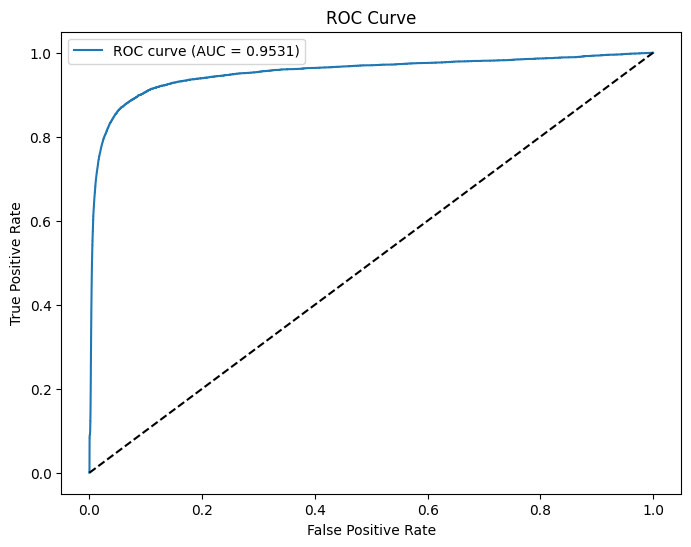

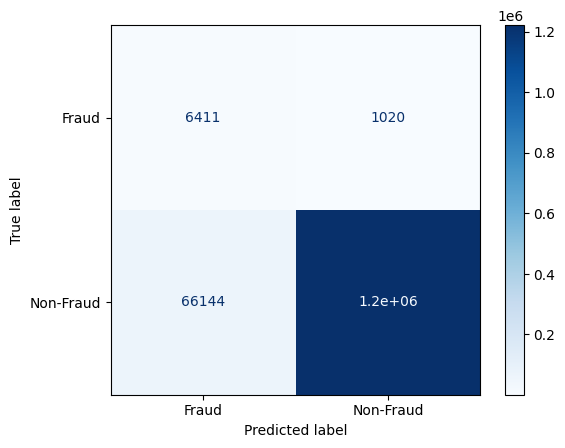

Threshold Used: 1.0000
         category_diversity  amt_rolling_mean_7d  age_spend_ratio       amt  \
1044647                 1.0             0.983927         1.000000  1.000000   
3535                    1.0             0.927946         0.968565  0.936813   
71323                   1.0             0.959710         0.912361  0.946152   
258453                  1.0             0.906060         0.884180  0.916927   
1065604                 1.0             0.853995         0.819879  0.866589   
1151456                 1.0             0.612515         0.584899  0.618222   
1044653                 1.0             1.000000         0.003965  0.003963   
1044650                 1.0             0.994341         0.010855  0.010853   
71326                   1.0             0.960938         0.002684  0.002783   
1044652                 1.0             0.997403         0.004355  0.004353   
1044651                 1.0             0.995058         0.002631  0.002629   
1044648                 1.0  

In [18]:
selected_card_features = [
    'category_diversity', 'amt_rolling_mean_7d', 'age_spend_ratio', 'amt',
    'amt_rolling_mean_15d', 'avg_daily_trans', 'num_trans_per_card',
    'distance_between_transactions', 'distance_between_cardholder_merchant'
]

result_df_filtered, threshold_used = autoencoder_on_iforest_anomalies(
    result_df=data_scaled,
    selected_features=selected_card_features,
    contamination=0.006,
    search_best_threshold=True
)

print(f"Threshold Used: {threshold_used:.4f}")

print(result_df_filtered.head(20))
